# Local Feature Importance Demo

This notebook demonstrates the proximity-based local feature importance added to `forestgap.core`. The example uses a synthetic classification dataset with continuous features (`make_classification`) and a permutation-based perturbation step to compute local feature contributions.

In [107]:
from pathlib import Path
import sys

for candidate in (Path.cwd(), Path.cwd() / "ObliqueProximitiesCode", Path.cwd().parent):
    if (candidate / "forestgap").exists():
        sys.path.insert(0, str(candidate))
        break

In [137]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

from aeon.classification.sklearn import RotationForestClassifier

from forestgap import with_sparse_proximity, datasets

In [109]:
# X, y = make_classification(
#     n_samples=160,
#     n_features=10,
#     n_informative=3,
#     n_redundant=2,
#     n_repeated=0,
#     n_classes=2,
#     class_sep=0.5,
#     flip_y=0.05,
#     random_state=321,
# )

# columns = [f"feature_{i}" for i in range(X.shape[1])]
# X_train = pd.DataFrame(X[:120], columns=columns)
# X_test = pd.DataFrame(X[120:], columns=columns)
# y_train = y[:120]
# y_test = y[120:]

In [110]:
data = datasets.load_openml_dataset(dataset_id = 61, as_frame=True)
X = data.X
y = pd.Categorical(data.y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=321)

In [111]:
ProxRandomForestClassifier = with_sparse_proximity(RandomForestClassifier)

model = ProxRandomForestClassifier(
    n_estimators=80,
    random_state=21,
    prox_method="original",
    matrix_type="sparse",
    # bootstrap=False,
    # max_features=None,
)
model.fit(X_train, y_train)

importance, closeness, directionality = model.local_feature_importance(
    X_test,
    labels=y_test,
    perturbation="permute",
    return_closeness=True,
    return_directionality=True,
)

summary = importance.copy()
summary.insert(0, "true_label", y_test)
summary.insert(1, "predicted_label", model.predict(X_test))
summary.head()

,true_label,predicted_label,sepallength,sepalwidth,petallength,petalwidth
47,Iris-setosa,Iris-setosa,-0.733603,-0.126969,-4.408729,-3.717835
120,Iris-virginica,Iris-virginica,-1.309550,-0.031354,-4.484566,-10.781425
108,Iris-virginica,Iris-virginica,-1.654851,-0.042729,-3.193453,-11.295097
65,Iris-versicolor,Iris-versicolor,-0.656066,-0.068422,-1.990359,0.836706
22,Iris-setosa,Iris-setosa,-0.832785,-0.105458,-4.606806,-4.813139


In [112]:
closeness["in_group"].sort_index()

,sepallength,sepalwidth,petallength,petalwidth
6,0.725196,0.890782,0.511218,0.501299
17,0.728103,0.888437,0.396631,0.430707
22,0.733017,0.895740,0.397902,0.366181
24,0.704317,0.891387,0.534221,0.429839
25,0.710379,0.893829,0.465967,0.380569
35,0.742313,0.882538,0.486946,0.269662
36,0.780848,0.731110,0.333427,0.256155
42,0.768347,0.881934,0.397478,0.461461
44,0.733518,0.872999,0.395784,0.454527
45,0.756755,0.889497,0.420080,0.401538


In [113]:
closeness['out_group'].sort_index()

,sepallength,sepalwidth,petallength,petalwidth
6,0.001683,0.000002,0.018957,0.021618
17,0.001669,0.000003,0.021853,0.024385
22,0.001071,0.000002,0.024942,0.030347
24,0.001854,0.000003,0.016974,0.023599
25,0.001819,0.000004,0.016607,0.026858
35,0.001576,0.000003,0.016743,0.032475
36,0.001248,0.001021,0.032411,0.043136
42,0.001367,0.000002,0.023915,0.028268
44,0.000084,0.000003,0.019739,0.023457
45,0.001259,0.000004,0.011938,0.025410


In [133]:
pd.concat([directionality['upward'], directionality['downward']], axis = 1).sort_index()

,sepallength,sepalwidth,petallength,petalwidth,sepallength,sepalwidth,petallength,petalwidth
6,-0.847788,0.000000,-4.290116,-5.304412,0.000000,-0.152697,0.000000,0.000000
17,-0.925129,0.000000,-4.878765,-5.970896,0.000000,-0.135087,NaN,0.000000
22,-0.832785,0.000000,-4.606806,-5.156934,NaN,-0.117176,NaN,0.000000
24,-0.874998,0.000000,-5.977911,-4.668702,NaN,-0.143867,0.000000,NaN
25,-0.412551,-0.194531,-6.033482,-4.997387,0.000000,-0.002417,0.000000,0.000000
35,-0.845022,0.000000,-4.348223,-6.139171,0.000000,-0.192209,0.000000,0.000000
36,-0.145468,0.044750,-3.347934,-4.543130,-0.412968,-0.040994,NaN,0.000000
42,-0.643587,0.000000,-4.697228,-3.999694,NaN,-0.195029,NaN,0.000000
44,-1.069477,0.000000,-6.330109,-5.658125,0.000000,-0.160986,0.000000,0.000000
45,-0.280541,-0.194531,-5.176038,-5.475547,0.000000,-0.002832,0.000000,0.000000


<Axes: xlabel='sepallength', ylabel='sepalwidth'>

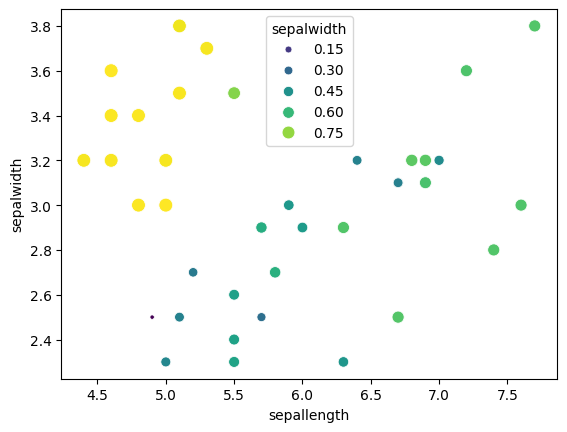

In [144]:
sns.scatterplot(x = X_test["sepallength"], y = X_test["sepalwidth"], hue=closeness["in_group"]['sepalwidth'], size=closeness["in_group"]['sepalwidth'], palette="viridis", sizes=(10, 100))

In [114]:
# Is there a relationship between diffuclty of prediction and the magnitude of local feature importance?

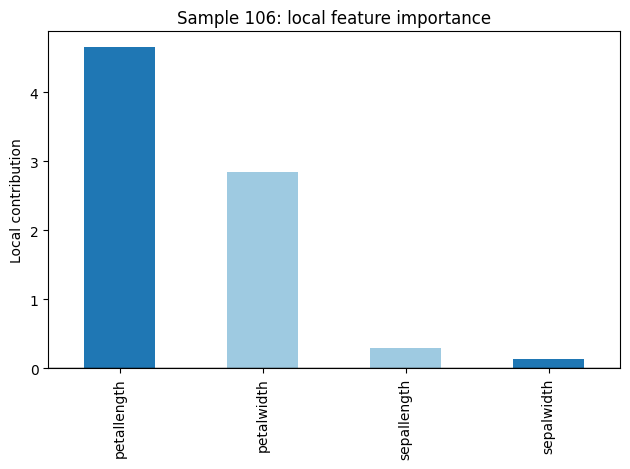

,importance,upward_effect,downward_effect,upward_count,downward_count
petallength,4.651391,2.338961,8.645590,19,11
petalwidth,2.840658,0.184666,3.806473,8,22
sepallength,0.291338,0.349511,0.000469,25,5
sepalwidth,0.131854,0.131854,NaN,30,0


In [115]:
# sample_id = importance.index[1]
sample_id = 106
sample_scores = importance.loc[sample_id].sort_values(key=np.abs, ascending=False)

ax = sample_scores.plot(kind="bar", color=["#1f77b4", "#9ecae1", "#9ecae1"])
ax.axhline(0.0, color="black", linewidth=1)
ax.set_ylabel("Local contribution")
ax.set_title(f"Sample {sample_id}: local feature importance")
plt.tight_layout()
plt.show()

sample_directionality = pd.DataFrame(
    {
        "importance": importance.loc[sample_id],
        "upward_effect": directionality["upward"].loc[sample_id],
        "downward_effect": directionality["downward"].loc[sample_id],
        "upward_count": directionality["upward_count"].loc[sample_id],
        "downward_count": directionality["downward_count"].loc[sample_id],
    }
).sort_values("importance", key=np.abs, ascending=False)

sample_directionality.head(6)

### How to read the sign of the local importance scores

- Positive means the observed feature value supported the focal class used for `local_feature_importance`.
- Negative means the observed feature value pushed the sample away from that focal class.
- A value near zero means perturbing that feature had little class-relative effect locally.
- This is not a monotone statement like "larger feature value increases the prediction". The sign is about the effect of the observed value under the chosen perturbation scheme, relative to the chosen focal class.
- When `return_directionality=True`, `upward` averages the same local score over perturbations that replaced the feature with a higher numeric value, while `downward` averages it over lower-value perturbations.
- Read `upward_effect` and `downward_effect` as directional perturbation summaries, not as exact derivatives. They describe what happened on average when the feature was pushed upward or downward under the chosen perturbation scheme.
- Compare the directional effects with the main `importance` column. If one direction has a much larger magnitude than the other, the local behavior is asymmetric around the observed value.
- `upward_count` and `downward_count` show how many perturbations contributed to each directional average. Small counts mean the directional summary is based on little support.
- A `NaN` directional effect means the notebook did not generate any perturbations in that direction for that sample-feature pair. For example, all tested quantiles may have fallen below the observed value, or all above it.
- For binary `flip`, directionality is usually less meaningful because the method only contrasts the observed level with the other level. The directional summary is most interpretable for ordered numeric features, especially with quantile-based perturbations.


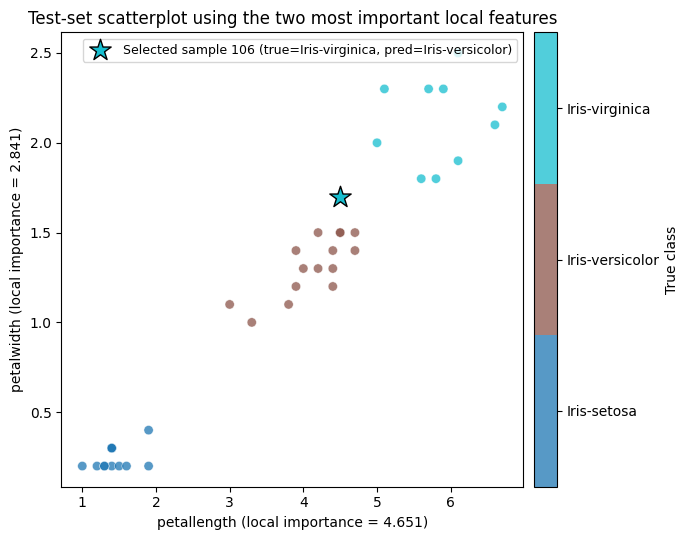

In [116]:
# -- Scatterplot of the two most important features for the selected sample --
top2_features = sample_scores.abs().nlargest(2).index.tolist()
feat_x, feat_y = top2_features

y_test_series = pd.Series(np.asarray(y_test), index=X_test.index, name="true_label")
class_names = list(y_test.categories)
class_to_code = {label: code for code, label in enumerate(class_names)}
y_test_codes = y_test_series.map(class_to_code)
plot_cmap = plt.get_cmap("tab10", len(class_names))

fig, ax = plt.subplots(figsize=(7, 5.5))

scatter = ax.scatter(
    X_test[feat_x],
    X_test[feat_y],
    c=y_test_codes,
    cmap=plot_cmap,
    s=45,
    alpha=0.75,
    edgecolors="white",
    linewidths=0.4,
    vmin=-0.5,
    vmax=len(class_names) - 0.5,
)

sample_true_label = y_test_series.loc[sample_id]
sample_pred_label = model.predict(X_test.loc[[sample_id]])[0]

ax.scatter(
    float(X_test.loc[sample_id, feat_x]),
    float(X_test.loc[sample_id, feat_y]),
    s=260,
    marker="*",
    c=[class_to_code[sample_true_label]],
    cmap=plot_cmap,
    vmin=-0.5,
    vmax=len(class_names) - 0.5,
    edgecolors="black",
    linewidths=1.0,
    zorder=5,
    label=(
        f"Selected sample {sample_id} "
        f"(true={sample_true_label}, pred={sample_pred_label})"
    ),
)

ax.set_xlabel(f"{feat_x} (local importance = {sample_scores[feat_x]:.3f})")
ax.set_ylabel(f"{feat_y} (local importance = {sample_scores[feat_y]:.3f})")
ax.set_title("Test-set scatterplot using the two most important local features")
ax.legend(fontsize=9, loc="best")

cbar = plt.colorbar(scatter, ax=ax, pad=0.02, ticks=range(len(class_names)))
cbar.set_ticklabels(class_names)
cbar.set_label("True class")

plt.tight_layout()
plt.show()

In [117]:
importance

,sepallength,sepalwidth,petallength,petalwidth
47,-0.733603,-0.126969,-4.408729,-3.717835
120,-1.309550,-0.031354,-4.484566,-10.781425
108,-1.654851,-0.042729,-3.193453,-11.295097
65,-0.656066,-0.068422,-1.990359,0.836706
22,-0.832785,-0.105458,-4.606806,-4.813139
50,-0.415786,-0.073125,-1.249376,0.765414
113,-0.819910,-0.029016,-0.450382,-3.692583
44,-0.962529,-0.155620,-5.064087,-4.337896
96,-0.701941,-0.074802,-4.416689,-2.208519
35,-0.732353,-0.134547,-4.203282,-5.934532


In [ ]:
# ── Scatterplot: training points colored & sized by proximity to a query ──────
obs_idx = 1  # change to any value in [0, 4] to select a different query

query_row = X_test.iloc[[obs_idx]]
query_label = y_test[obs_idx]
query_sample_id = X_test.index[obs_idx]

# Proximity of query to every training point  (shape: 1 × n_train)
prox_row = model.prox_extend(query_row)
if hasattr(prox_row, "toarray"):
    prox_row = prox_row.toarray()
prox_weights = prox_row.ravel()

# Choose axes: top-2 features by |importance| for this observation
imp_scores = importance.loc[query_sample_id]
top2 = imp_scores.abs().nlargest(2).index.tolist()
feat_x, feat_y = top2

# Scale marker sizes proportionally to proximity weight
max_prox = prox_weights.max()
s_vals = 20 + 280 * (prox_weights / max_prox if max_prox > 0 else prox_weights)

fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    X_train[feat_x], X_train[feat_y],
    c=prox_weights,
    s=s_vals,
    cmap="plasma",
    alpha=0.75,
    edgecolors="none",
    label="Training points",
)
plt.colorbar(sc, ax=ax, label="Proximity to query")

ax.scatter(
    query_row[feat_x], query_row[feat_y],
    c="red", s=220, marker="*", zorder=5,
    edgecolors="black", linewidths=0.8,
    label=f"Query  (y={query_label}, pred={model.predict(query_row)[0]})",
)

ax.set_xlabel(f"{feat_x}  (importance = {imp_scores[feat_x]:.3f})")
ax.set_ylabel(f"{feat_y}  (importance = {imp_scores[feat_y]:.3f})")
ax.set_title(
    f"Training-point proximity to observation {query_sample_id}\n"
    f"axes = top-2 importance features"
)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

IndexError: index 106 is out of bounds for axis 0 with size 38

## Beeswarm-style summary

A beeswarm-style plot is a reasonable summary for `local_feature_importance`, because it shows the distribution of signed local contribution scores across many observations. Unlike SHAP, these scores are not additive feature attributions, so this plot should be interpreted as a distributional summary in proximity space rather than a decomposition of the model output.

To make the sign comparable across samples, fix a single focal class for every observation in the batch. In the cells below, the focal class is chosen from the observed training labels. Positive values mean the original feature value supported that focal class, and negative values mean it moved the observation away from that focal class.

In [119]:
len(X_test)

38

In [120]:
# -- Compute a batch of local contributions for one fixed focal class --
beeswarm_X = X_test.iloc[:37].copy()
observed_classes = list(y_train.categories)
focal_class = observed_classes[0]
focal_labels = np.repeat(focal_class, len(beeswarm_X))

beeswarm_importance, beeswarm_directionality = model.local_feature_importance(
    beeswarm_X,
    labels=focal_labels,
    perturbation="permute",
    n_repeats=6,
    random_state=0,
    return_directionality=True,
)

top_features = (
    beeswarm_importance.abs().mean()
    .sort_values(ascending=False)
    .head(6)
    .index.tolist()
)

beeswarm_importance[top_features].head()

,petalwidth,petallength,sepallength,sepalwidth
47,-5.910558,-5.080144,-0.879660,-0.129687
120,11.243551,7.307486,1.691091,0.017734
108,10.086026,8.933160,1.665492,0.036458
65,3.101427,2.294918,0.571249,0.109062
22,-5.105613,-1.552235,-0.647525,-0.138229


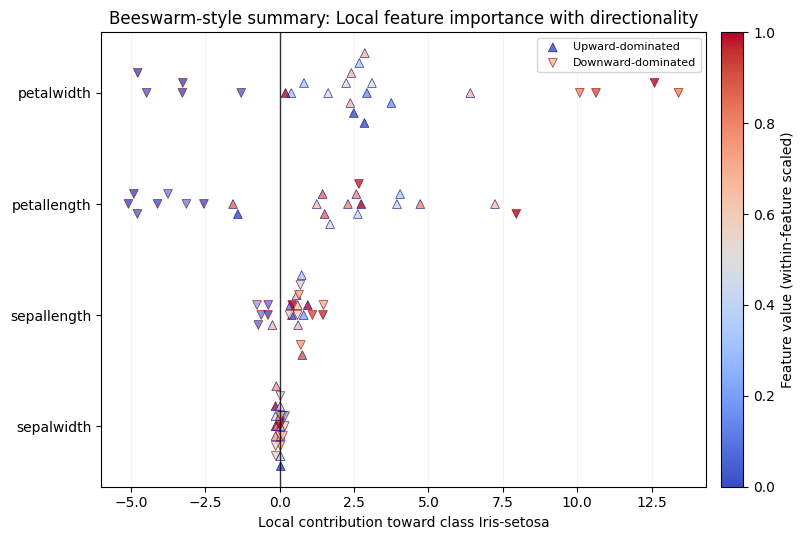

In [121]:
# -- Prototype beeswarm plot for proximity-based local importance with directionality --
def beeswarm_offsets_with_directionality(values, directionality_diff, step=0.08, bins=18):
    """Compute offsets accounting for directionality asymmetry.
    directionality_diff: upward_effect - downward_effect (positive = upward-dominated).
    """
    values = np.asarray(values, dtype=float)
    directionality_diff = np.asarray(directionality_diff, dtype=float)
    
    if values.size == 0:
        return np.array([]), np.array([])
    if np.allclose(values, values[0]):
        return np.zeros_like(values), np.zeros_like(values)

    order = np.argsort(values)
    sorted_values = values[order]
    sorted_dir_diff = directionality_diff[order]
    
    edges = np.linspace(sorted_values.min(), sorted_values.max(), bins + 1)
    bucket_ids = np.digitize(sorted_values, edges[1:-1], right=False)

    sorted_offsets = np.zeros_like(sorted_values)
    directional_signs = np.ones_like(sorted_values)  # +1 upward-dominated, -1 downward-dominated
    
    for bucket in np.unique(bucket_ids):
        idx = np.where(bucket_ids == bucket)[0]
        pattern = [0.0]
        for k in range(1, len(idx)):
            level = (k + 1) // 2
            sign = 1.0 if k % 2 else -1.0
            pattern.append(sign * level * step)
        sorted_offsets[idx] = np.array(pattern)
        # Mark directionality: upward-dominated (>0) vs downward-dominated (<0)
        directional_signs[idx] = np.sign(sorted_dir_diff[idx])

    offsets = np.zeros_like(values)
    offsets[order] = sorted_offsets
    dir_signs_out = np.ones_like(values)
    dir_signs_out[order] = directional_signs
    
    return offsets, dir_signs_out


fig, ax = plt.subplots(figsize=(8.5, 5.5))
plot_features = list(reversed(top_features))

for y_pos, feature in enumerate(plot_features):
    contributions = beeswarm_importance[feature].to_numpy(dtype=float)
    feature_values = beeswarm_X[feature].to_numpy(dtype=float)
    
    # Get directionality information
    upward_eff = beeswarm_directionality["upward"][feature].to_numpy(dtype=float)
    downward_eff = beeswarm_directionality["downward"][feature].to_numpy(dtype=float)
    dir_diff = upward_eff - downward_eff
    
    offsets, dir_signs = beeswarm_offsets_with_directionality(contributions, dir_diff, step=0.09, bins=20)

    lo, hi = np.nanpercentile(feature_values, [5, 95])
    if np.isclose(lo, hi):
        scaled_values = np.full_like(feature_values, 0.5, dtype=float)
    else:
        scaled_values = np.clip((feature_values - lo) / (hi - lo), 0, 1)

    # Split into upward-dominated and downward-dominated for different markers
    upward_mask = dir_signs > 0
    downward_mask = dir_signs < 0
    balanced_mask = dir_signs == 0
    
    # Upward-dominated: ^ marker with navy edge
    if np.any(upward_mask):
        ax.scatter(
            contributions[upward_mask],
            np.full(np.sum(upward_mask), y_pos, dtype=float) + offsets[upward_mask],
            c=scaled_values[upward_mask],
            cmap="coolwarm",
            marker="^",
            s=40,
            alpha=0.8,
            edgecolors="navy",
            linewidths=0.5,
            label="Upward-dominated" if y_pos == 0 else "",
        )
    
    # Downward-dominated: v marker with maroon edge
    if np.any(downward_mask):
        ax.scatter(
            contributions[downward_mask],
            np.full(np.sum(downward_mask), y_pos, dtype=float) + offsets[downward_mask],
            c=scaled_values[downward_mask],
            cmap="coolwarm",
            marker="v",
            s=40,
            alpha=0.8,
            edgecolors="maroon",
            linewidths=0.5,
            label="Downward-dominated" if y_pos == 0 else "",
        )
    
    # Balanced (no directionality asymmetry): o marker
    if np.any(balanced_mask):
        ax.scatter(
            contributions[balanced_mask],
            np.full(np.sum(balanced_mask), y_pos, dtype=float) + offsets[balanced_mask],
            c=scaled_values[balanced_mask],
            cmap="coolwarm",
            marker="o",
            s=28,
            alpha=0.8,
            edgecolors="gray",
            linewidths=0.3,
            label="Balanced" if y_pos == 0 else "",
        )

ax.axvline(0.0, color="black", linewidth=1, alpha=0.8)
ax.set_yticks(range(len(plot_features)))
ax.set_yticklabels(plot_features)
ax.set_xlabel(f"Local contribution toward class {focal_class}")
ax.set_title("Beeswarm-style summary: Local feature importance with directionality")
ax.grid(axis="x", alpha=0.15)
ax.legend(loc="upper right", fontsize=8)

sm = plt.cm.ScalarMappable(cmap="coolwarm")
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Feature value (within-feature scaled)")

plt.tight_layout()
plt.show()

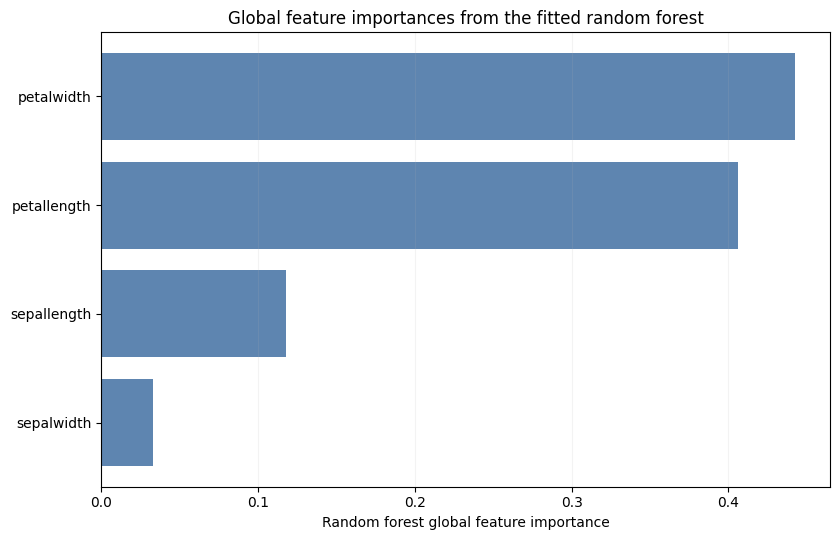

In [122]:
# -- Global random-forest feature importance for comparison --
global_importance = pd.Series(model.feature_importances_, index=X_train.columns)
global_importance = global_importance.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(global_importance.index, global_importance.values, color="#4C78A8", alpha=0.9)
ax.set_xlabel("Random forest global feature importance")
ax.set_title("Global feature importances from the fitted random forest")
ax.grid(axis="x", alpha=0.15)
plt.tight_layout()
plt.show()

100%|██████████| 38/38 [00:00<00:00, 65.94it/s]


SHAP beeswarm class: Iris-setosa (index=0)


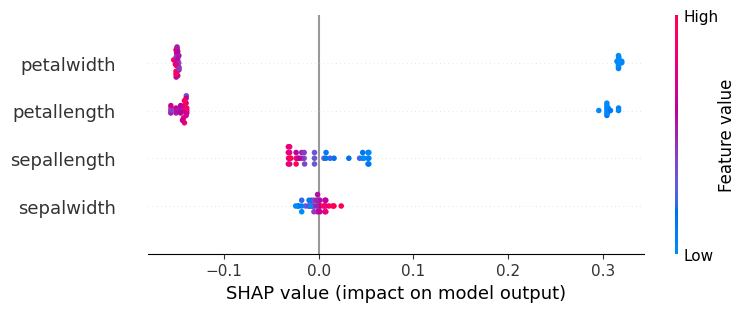

In [123]:
# -- Model-agnostic SHAP (KernelExplainer) on the trained forest + beeswarm plot --
try:
    import shap
except ImportError as exc:
    raise ImportError(
        "The `shap` package is required for this section. Install with `pip install shap`."
    ) from exc

shap_X = X_test.copy()

# Use a background sample from training data for KernelExplainer
background = shap.sample(X_train, min(100, len(X_train)), random_state=0)

# KernelExplainer is model-agnostic: it only needs a prediction function
explainer = shap.KernelExplainer(model.predict_proba, background)
shap_values = explainer(shap_X)

# For multiclass outputs, select one class slice for beeswarm.
model_classes = list(model.classes_)
shap_class = focal_class if "focal_class" in globals() and focal_class in model_classes else model_classes[0]

if len(shap_values.shape) == 3:
    class_idx = model_classes.index(shap_class)
    shap_to_plot = shap_values[:, :, class_idx]
    print(f"SHAP beeswarm class: {shap_class} (index={class_idx})")
else:
    shap_to_plot = shap_values
    print("SHAP beeswarm uses single-output values.")

shap.plots.beeswarm(shap_to_plot, max_display=10)